[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HernanBustamanteG/lapis26-p3-corrientes/blob/main/notebooks/07_hito6_interpretacion.ipynb)

# 07 · Hito 6: corrientes observadas y temas avanzados

**Qué pide el enunciado.** Comparar con Sagitario (dos vueltas, ~20–100 kpc), Orphan–Chenab y las corrientes de
S5: ¿dónde caerían en la clasificación? Y, como temas avanzados: variar la masa de la LMC, separar la precesión de
un halo achatado de la perturbación de la LMC, y la no linealidad (notebook 05).

**Cómo se ubica una corriente real.** Con las trazas de `galstreams` (Mateu 2023): se pasan las posiciones de la
traza al marco de la MW (el mismo Sol que el resto del proyecto) y se ajusta el plano por el centro de la MW (SVD);
si la traza tiene movimientos propios **y** velocidad radial, el sentido de giro sale de $\mathbf L = \mathbf x \times \mathbf v$.
Se buscan en el catálogo las corrientes con el **polo de hoy** (modelo D) a menos de 30° y con radios que se solapan.
Es una ubicación aproximada (la grilla tiene polos cada ~30°), no un ajuste de cada corriente.

In [24]:
# Celda 1: entorno. En Colab clona el repositorio, instala versiones fijas y monta Google Drive (las salidas
# quedan en MyDrive/lapis26_p3/salidas). Si numpy cambia de version, la sesion se reinicia UNA vez:
# vuelve a ejecutar esta celda. En una maquina propia solo comprueba versiones.
import os, sys, subprocess
REPO_URL = "https://github.com/HernanBustamanteG/lapis26-p3-corrientes.git"
USAR_DRIVE = True
if "google.colab" in sys.modules:
    RAIZ = "/content/lapis26-p3-corrientes"
    if not os.path.isdir(RAIZ):
        subprocess.run(["git", "clone", "-q", REPO_URL, RAIZ], check=True)
else:
    RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
from p3streams import entorno
if entorno.en_colab():
    entorno.preparar_colab(RAIZ, montar_drive=USAR_DRIVE)
entorno.resumen();

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python 3.13.18
  numpy       2.2.6
  scipy       1.16.3
  astropy     7.2.3
  gala        1.12.0
  matplotlib  3.10.0
  pandas      2.2.3
  healpy      1.20.1
  galstreams  1.2.1
Salidas en: /content/drive/MyDrive/lapis26_p3/salidas
ffmpeg: /usr/bin/ffmpeg | CPU: 2
Entorno OK


In [25]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
import matplotlib.pyplot as plt
from p3streams import config as C, util as U, estilo as E
E.usar()
SAL = U.carpeta_nueva("07_hito6")          # carpeta nueva de este notebook (nada se pisa)
FUENTE = "notebooks/07_hito6.ipynb, p3streams " + C.VERSION + ", " + U.ahora()
print("Salidas de este notebook:", SAL)

Salidas de este notebook: /content/drive/MyDrive/lapis26_p3/salidas/07_hito6_20261030_025457


In [26]:
from p3streams import resultados as R, analisis as An, metricas as Me, figuras as F, potenciales as P
PROPIOS = True
DF, ORIGEN = R.cargar("catalogo_principal", propios=PROPIOS)
print("Catalogo: %d corrientes, leido de %s" % (len(DF), ORIGEN))
sis = P.integrar_sistema()          # el mismo sistema MW + LMC (1.8e11 Msun) del catalogo
DF = An.agregar_geometria(DF, sis)
from p3streams import interpretar as I
MWS = I.cargar_galstreams()
REALES = [I.corriente_real(MWS, n) for n in I.REALES]
TR = pd.DataFrame([{k: (np.round(v, 3).tolist() if isinstance(v, np.ndarray) else v) for k, v in r.items()} for r in REALES])
TR

Catalogo: 288 corrientes, leido de /content/drive/MyDrive/lapis26_p3/salidas/principal_20261029_140326
Initializing galstreams library from master_log... 


,nombre,normal,sentido_conocido,r_min,r_max,r_med,n_puntos,has_pm,has_vrad,ref
0,Sagittarius-A20,"[0.065, -0.971, -0.231]",False,18.899717,47.681116,29.374068,28000,True,False,antoja2020
1,Orphan-K23,"[-0.722, -0.035, -0.691]",True,14.956960,58.647102,20.048206,18113,True,True,koposov2023
2,AAU-ATLAS-L21,"[0.903, -0.082, -0.422]",True,20.740451,27.910438,23.573579,2350,True,True,li2021
3,AAU-AliqaUma-L21,"[0.893, 0.014, -0.449]",True,28.050907,33.271941,30.427038,950,True,True,li2021
4,Elqui-S19,"[0.933, -0.359, 0.003]",True,49.794275,50.342555,50.080306,1094,True,True,shipp2019
5,Indus-S19,"[-0.712, 0.619, -0.331]",True,12.694923,14.598447,13.634432,1820,True,True,shipp2019
6,Jhelum-a-B19,"[0.448, -0.881, 0.15]",False,9.379573,13.253299,11.329249,3000,True,False,bonaca2019
7,Phoenix-S19,"[0.484, 0.716, -0.503]",True,17.771198,19.150001,18.486285,1175,True,True,shipp2019
8,Turranburra-S19,"[-0.672, 0.316, 0.67]",False,32.759987,32.940918,32.912945,1370,True,False,shipp2019
9,TucanaIII-S19,"[-0.62, 0.688, -0.378]",False,21.172436,25.107400,23.137004,426,True,False,shipp2019


In [27]:
TAB = I.resumen(REALES, DF, metrica="desalineamiento_deg").round(2)
TAB.to_csv(os.path.join(SAL, "hito6_corrientes_reales.csv"), index=True)
TAB

,stream,r_kpc,sense_known,n_neighbours,f_reflex_misalignment,f_reflex_pole,class_misalignment,class_pole
0,Sagittarius-A20,19-48,False,39,0.57,0.46,mixed,mixed
1,Orphan-K23,15-59,True,20,0.32,0.30,torque,torque
2,AAU-ATLAS-L21,21-28,True,17,0.50,0.35,mixed,torque
3,AAU-AliqaUma-L21,28-33,True,15,0.52,0.37,mixed,torque
4,Elqui-S19,50-50,True,17,0.44,0.30,mixed,torque
5,Indus-S19,13-15,True,10,0.26,0.23,torque,torque
6,Jhelum-a-B19,9-13,False,10,0.47,0.30,mixed,torque
7,Phoenix-S19,18-19,True,12,0.48,0.38,mixed,torque
8,Turranburra-S19,33-33,False,44,0.58,0.42,mixed,mixed
9,TucanaIII-S19,21-25,False,35,0.43,0.32,mixed,torque


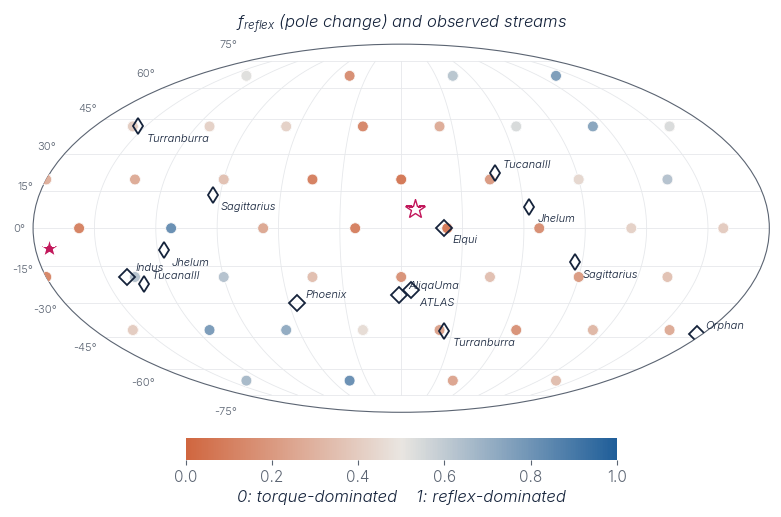

Figura: hito6_mapa_reales.png 
Milestone 6. Reflex fraction of the pole change for the catalogue streams (colour, at their initial poles) and the orbital-plane normals of observed streams from galstreams tracks (diamonds; open thin diamonds: both orientations, when the track has no radial velocities to fix the sense of rotation). Star: LMC orbital pole. Galactocentric frame, Mollweide.


In [28]:
fig = F.mapa_polos(DF.assign(_f=DF["dpolo_f_reflex_todo"]), ["_f"], [r"$f_{\rm reflex}$ (pole change) and observed streams"],
                   sis=sis, cmaps={"_f": F.cmap_f_reflex()}, rangos={"_f": (0, 1)},
                   etiquetas={"_f": "0: torque-dominated    1: reflex-dominated"})
A = fig.axes[0]
fig.set_size_inches(9.5, 5.6)
for j, r in enumerate(REALES):
    for sg in ((1,) if r["sentido_conocido"] else (1, -1)):
        lo, la = F.lb(sg * r["normal"])
        A.plot(-lo, la, "D" if r["sentido_conocido"] else "d", ms=8, mfc="none", mec=E.TINTA, mew=1.3, zorder=5)
        A.annotate(r["nombre"].split("-")[0] if not r["nombre"].startswith("AAU") else r["nombre"].split("-")[1],
                   (-lo[0], la[0]), xytext=(6, 4 if j % 2 else -11), textcoords="offset points", fontsize=8, color=E.TINTA)
PIE = 'Milestone 6. Reflex fraction of the pole change for the catalogue streams (colour, at their initial poles) and the orbital-plane normals of observed streams from galstreams tracks (diamonds; open thin diamonds: both orientations, when the track has no radial velocities to fix the sense of rotation). Star: LMC orbital pole. Galactocentric frame, Mollweide.'
E.guardar(fig, os.path.join(SAL, 'hito6_mapa_reales.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito6_mapa_reales.png', "\n" + PIE)

### Masa de la LMC

Cuatro catálogos iguales (12 polos HEALPix × 3 familias) con $M_{\rm LMC}$ = 1.0, 1.5, 1.8 y 2.5 × 10¹¹ M☉: el sistema
MW + LMC se integra de nuevo para cada masa (la órbita pasada de la LMC cambia con su masa).

No hay corrida propia de catalogo_masa_1.0 en /content/drive/MyDrive/lapis26_p3/salidas: uso la incluida en el repositorio.
No hay corrida propia de catalogo_masa_1.5 en /content/drive/MyDrive/lapis26_p3/salidas: uso la incluida en el repositorio.
No hay corrida propia de catalogo_masa_1.8 en /content/drive/MyDrive/lapis26_p3/salidas: uso la incluida en el repositorio.
No hay corrida propia de catalogo_masa_2.5 en /content/drive/MyDrive/lapis26_p3/salidas: uso la incluida en el repositorio.


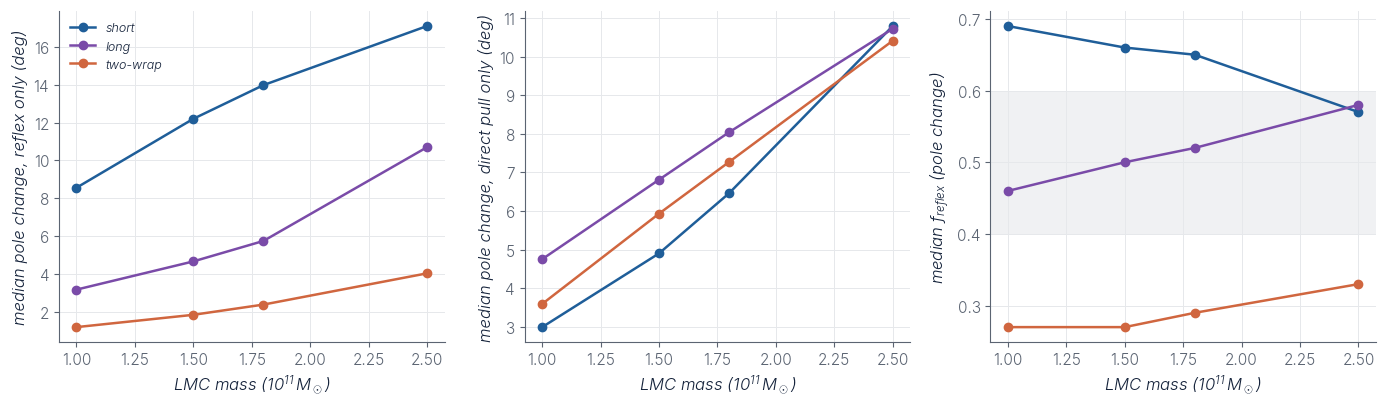

Figura: hito6_masa_lmc.png 
Advanced topic: LMC mass. Median pole change caused by the reflex motion alone and by the direct pull alone, and median reflex fraction, for 12 HEALPix poles x 3 stream families, re-integrating the MW + LMC system for each LMC mass. Grey band: mixed (0.4 < f_reflex < 0.6).


,M_LMC,familia,reflex,direct,full,f_reflex,desal_full,n
0,1.0,corta,8.56,2.99,6.38,0.69,3.83,12
1,1.0,doble,1.20,3.59,2.13,0.27,0.68,12
2,1.0,larga,3.18,4.75,2.33,0.46,0.68,12
3,1.5,corta,12.20,4.90,9.43,0.66,6.29,12
4,1.5,doble,1.85,5.93,3.15,0.27,1.99,12
5,1.5,larga,4.67,6.81,3.72,0.50,1.22,12
6,1.8,corta,13.98,6.46,11.25,0.65,8.13,12
7,1.8,doble,2.39,7.27,3.80,0.29,2.33,12
8,1.8,larga,5.75,8.04,4.62,0.52,1.83,12
9,2.5,corta,17.10,10.79,15.44,0.57,11.59,12


In [29]:
filas = []
for m in ("1.0", "1.5", "1.8", "2.5"):
    d, _ = R.cargar("catalogo_masa_" + m, propios=PROPIOS)
    for fam, g in d.groupby("familia"):
        filas.append(dict(M_LMC=float(m), familia=fam, reflex=g["dpolo_B_todo"].median(), direct=g["dpolo_C_todo"].median(),
                          full=g["dpolo_D_todo"].median(), f_reflex=g["dpolo_f_reflex_todo"].median(),
                          desal_full=g["dM_full_desalineamiento_deg_todo"].abs().median(), n=len(g)))
MAS = pd.DataFrame(filas).round(2)
MAS.to_csv(os.path.join(SAL, "hito6_masa_lmc.csv"), index=False)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
for fam in ("corta", "larga", "doble"):
    g = MAS[MAS["familia"] == fam]
    col = F.COLOR_FAMILIA[fam]
    ax[0].plot(g["M_LMC"], g["reflex"], "-o", color=col, label=F.NOMBRE_FAMILIA[fam])
    ax[1].plot(g["M_LMC"], g["direct"], "-o", color=col)
    ax[2].plot(g["M_LMC"], g["f_reflex"], "-o", color=col)
ax[0].set_ylabel("median pole change, reflex only (deg)")
ax[1].set_ylabel("median pole change, direct pull only (deg)")
ax[2].set_ylabel(r"median $f_{\rm reflex}$ (pole change)")
ax[2].axhspan(0.4, 0.6, color=E.GRILLA, alpha=0.6, lw=0)
for A in ax:
    A.set_xlabel(r"LMC mass ($10^{11}\,M_\odot$)"); E.grilla(A)
ax[0].legend(fontsize=9)
fig.tight_layout()
PIE = 'Advanced topic: LMC mass. Median pole change caused by the reflex motion alone and by the direct pull alone, and median reflex fraction, for 12 HEALPix poles x 3 stream families, re-integrating the MW + LMC system for each LMC mass. Grey band: mixed (0.4 < f_reflex < 0.6).'
E.guardar(fig, os.path.join(SAL, 'hito6_masa_lmc.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito6_masa_lmc.png', "\n" + PIE)
MAS

### Halo achatado contra LMC

Un halo achatado también hace precesar los polos orbitales, salvo en órbitas polares (enunciado). Se compara el
cambio del polo que produce un halo con $c/a = 0.8$ (sin LMC) con el que produce la LMC (modelo D), para una
órbita polar y una inclinada 45°, en la familia larga.

In [32]:
import time
import gala.potential as gp, astropy.units as u
from gala.units import galactic
from p3streams import potenciales as P, corrientes as Co, catalogo as Ca
def mw_achatada(c=0.8):
    p = gp.CCompositePotential()
    for k, v in P.componentes_mw().items():
        p[k] = v
    p["halo"] = gp.LeeSutoTriaxialNFWPotential(units=galactic, v_c=C.MW_HALO["v_c"] * u.km / u.s,
                                               r_s=C.MW_HALO["r_s"] * u.kpc, a=1.0, b=1.0, c=c)
    return p
MODS = P.modelos(sis)
POT = {"A": MODS["A"], "D": MODS["D"], "A_flat": mw_achatada(0.8)}
fam = Ca.FAMILIAS["larga"]
filas = []
for nombre, polo in (("polar", [0.0, -1.0, 0.0]), ("inclined 45 deg", [0.0, -np.sqrt(0.5), np.sqrt(0.5)])):
    x0, v0 = Co.condiciones_iniciales(polo, fam["r_apo"], 0.5, 0.0)
    t0 = time.time()
    pol = {k: Me.polo_medio(Me.polos(*(np.asarray(Co.generar(p, x0, v0, m_prog=fam["m_prog"], t_inicio=-C.T_START)[q], float)
                                        for q in ("pos", "vel")))) for k, p in POT.items()}
    filas.append({"orbit": nombre, "pole change, flattened halo c/a = 0.8 (deg)": Me.angulo(pol["A_flat"], pol["A"]),
                  "pole change, LMC (D vs A) (deg)": Me.angulo(pol["D"], pol["A"]),
                  "pole tilt from initial, spherical A (deg)": Me.angulo(pol["A"], polo), "s": round(time.time() - t0)})
HALO = pd.DataFrame(filas).round(2)
HALO.to_csv(os.path.join(SAL, "hito6_halo_achatado.csv"), index=True)
HALO

,orbit,"pole change, flattened halo c/a = 0.8 (deg)","pole change, LMC (D vs A) (deg)","pole tilt from initial, spherical A (deg)",s
0,polar,0.04,2.38,0.02,99
1,inclined 45 deg,60.07,2.57,8.76,92


## Discusión del hito 6 y de los temas avanzados

**Dónde caen las corrientes observadas** (tabla de arriba; ubicación aproximada, no un ajuste):
- **Orphan–Chenab** (15–59 kpc, sentido conocido): sus vecinas del catálogo están dominadas por el **torque**
  ($f_{\rm reflex}$ ≈ 0.3 en las dos métricas) [comprobado en el catálogo]. Es coherente con la literatura, que
  atribuye su desalineamiento a la LMC (Koposov et al. 2019; Erkal et al. 2019) [conocimiento general: verificar
  los detalles en los artículos].
- **Corrientes de S5** (ATLAS, Aliqa Uma, Elqui, Indus, Jhelum, Phoenix, Turranburra, Tucana III; 9–50 kpc): mixtas
  por el desalineamiento y casi todas **torque** por el cambio del polo; Indus (13–15 kpc) es la más claramente de
  torque [comprobado en el catálogo]. Están en el rango de radios donde, estrella por estrella, los dos efectos se
  cancelan en parte (notebook 05).
- **Sagitario**: queda **mixta**, pero con tres advertencias. La traza de galstreams usada cubre 19–48 kpc, no los
  ~100 kpc del brazo lejano. Sin velocidades radiales en esa traza, el sentido de giro queda indeterminado. Y Sgr es
  masiva y su propia dinámica no está en estos modelos [deducido].
- Ninguna corriente observada de la lista cae entre las claramente dominadas por el reflejo: esas son las que
  están más allá de ~70–100 kpc (notebook 05).

**Masa de la LMC** [comprobado]: las perturbaciones crecen con la masa (el cambio del polo por reflejo en las
cortas: ~9° con $10^{11}\,M_\odot$, ~17° con $2.5\times10^{11}$). En cambio, $f_{\rm reflex}$ apenas se mueve: las
cortas siguen dominadas por el reflejo (0.69 → 0.57) y las de dos vueltas por el torque (0.27 → 0.33). La
clasificación es robusta a la masa de la LMC en este rango. La amplitud no lo es: por eso la amplitud sirve
para pesar la LMC (Shipp et al. 2021; Erkal et al. 2019).

**Halo achatado contra LMC** [comprobado]: con $c/a = 0.8$, la órbita polar casi no precesa (~0.04°), pero la inclinada
45° cambia su polo ~60° en 5 Gyr, contra ~2.6° por la LMC. **Fuera de las órbitas polares, la forma del halo
domina sobre la LMC**, y hay que modelarla junto con la LMC. Las corrientes polares son las sondas más limpias.

**Qué mediría primero con datos reales** [opinión, fundada en los notebooks 05 y 06]: el desalineamiento del movimiento
propio a lo largo de corrientes largas del sur con LSST. Es intrínseco, no necesita velocidades radiales y LSST lo
mide bien hasta ~40 kpc. Después vendría la dispersión de los polos con seguimiento espectroscópico, en las
corrientes externas, que son las que llevan la señal del reflejo.